Here I gonna work on all the sensors together, and run the analysis to see if when sensors is next to restaurants, the concentration of PM2.5 goes higher

In [31]:
import pandas as pd
df = pd.read_csv("/Users/apollinelamy/Desktop/data journalism/fall 2026/Air Pollution Data/notebooks/air_pollution.csv")
print(df)

                 time_stamp  sensor_index  pm2.5_atm  pm2.5_cf_1  \
0      2026-06-02T23:00:00Z        172823        4.8         4.8   
1      2026-06-02T17:00:00Z        172823        5.2         5.2   
2      2026-06-02T14:00:00Z        172823        4.3         4.3   
3      2026-06-02T06:00:00Z        172823        6.1         6.1   
4      2026-06-01T20:00:00Z        172823        4.9         4.9   
...                     ...           ...        ...         ...   
27091  2026-09-28T08:00:00Z        184329        1.3         1.3   
27092  2026-09-28T02:00:00Z        184329        0.4         0.4   
27093  2026-09-28T23:00:00Z        184329        1.7         1.7   
27094  2026-09-28T19:00:00Z        184329        1.5         1.5   
27095  2026-09-28T11:00:00Z        184329        1.5         1.5   

                zone  
0         restaurant  
1         restaurant  
2         restaurant  
3         restaurant  
4         restaurant  
...              ...  
27091  no restaurant  

In [32]:
df["sensor_index"]

0        172823
1        172823
2        172823
3        172823
4        172823
          ...  
27091    184329
27092    184329
27093    184329
27094    184329
27095    184329
Name: sensor_index, Length: 27096, dtype: int64

In [33]:
## this is giving me that I have ten sensors ##
df["sensor_index"].unique()

array([172823, 295845, 189249,  29183, 150174, 285560, 306402,  90247,
       319136, 184329])

perhaps my time should be my index

In [34]:
df['time_stamp'].dtype


<StringDtype(storage='python', na_value=nan)>

Knowing that, I need to convert my time stamp into a time that Python can understand

In [35]:
df["time_stamp"] = pd.to_datetime(df["time_stamp"])

In [36]:
print(df)

                     time_stamp  sensor_index  pm2.5_atm  pm2.5_cf_1  \
0     2026-06-02 23:00:00+00:00        172823        4.8         4.8   
1     2026-06-02 17:00:00+00:00        172823        5.2         5.2   
2     2026-06-02 14:00:00+00:00        172823        4.3         4.3   
3     2026-06-02 06:00:00+00:00        172823        6.1         6.1   
4     2026-06-01 20:00:00+00:00        172823        4.9         4.9   
...                         ...           ...        ...         ...   
27091 2026-09-28 08:00:00+00:00        184329        1.3         1.3   
27092 2026-09-28 02:00:00+00:00        184329        0.4         0.4   
27093 2026-09-28 23:00:00+00:00        184329        1.7         1.7   
27094 2026-09-28 19:00:00+00:00        184329        1.5         1.5   
27095 2026-09-28 11:00:00+00:00        184329        1.5         1.5   

                zone  
0         restaurant  
1         restaurant  
2         restaurant  
3         restaurant  
4         restaurant

In [37]:
## this is to check if I have some null datas##
df.isnull().sum()

time_stamp      0
sensor_index    0
pm2.5_atm       0
pm2.5_cf_1      0
zone            0
dtype: int64

In [38]:
## this is to check if I have any duplicates ## 
df.duplicated().sum()

np.int64(0)

In [39]:
df["time_stamp"].value_counts().head(30)

time_stamp
2026-08-06 05:00:00+00:00    10
2026-08-06 06:00:00+00:00    10
2026-08-06 02:00:00+00:00    10
2026-08-06 09:00:00+00:00    10
2026-08-06 10:00:00+00:00    10
2026-08-06 14:00:00+00:00    10
2026-08-07 01:00:00+00:00    10
2026-08-07 08:00:00+00:00    10
2026-08-07 14:00:00+00:00    10
2026-08-07 18:00:00+00:00    10
2026-08-08 12:00:00+00:00    10
2026-08-08 16:00:00+00:00    10
2026-08-08 03:00:00+00:00    10
2026-08-08 01:00:00+00:00    10
2026-08-04 06:00:00+00:00    10
2026-08-04 16:00:00+00:00    10
2026-08-04 17:00:00+00:00    10
2026-08-04 09:00:00+00:00    10
2026-08-04 18:00:00+00:00    10
2026-08-04 12:00:00+00:00    10
2026-08-09 18:00:00+00:00    10
2026-08-09 03:00:00+00:00    10
2026-08-09 14:00:00+00:00    10
2026-08-09 05:00:00+00:00    10
2026-08-09 09:00:00+00:00    10
2026-08-09 21:00:00+00:00    10
2026-08-09 12:00:00+00:00    10
2026-08-05 11:00:00+00:00    10
2026-08-05 21:00:00+00:00    10
2026-08-05 08:00:00+00:00    10
Name: count, dtype: int64

This indicates me that python understands that the dates are the same for the sensor

In [41]:
analysis = df.pivot_table(
    index="time_stamp",
    columns=["zone", "sensor_index"],
    values="pm2.5_atm"
).sort_index()

In [42]:
analysis

zone                      no restaurant                              \
sensor_index                     90247  184329 285560 306402 319136   
time_stamp                                                            
2026-06-01 00:00:00+00:00           2.2    1.4    8.0    4.5    NaN   
2026-06-01 01:00:00+00:00           2.1    1.7    8.2    1.3    NaN   
2026-06-01 02:00:00+00:00           2.1    1.6    9.9    0.3    NaN   
2026-06-01 03:00:00+00:00           2.1    1.8    9.8    0.2    NaN   
2026-06-01 04:00:00+00:00           2.3    1.6    7.8    0.3    NaN   
...                                 ...    ...    ...    ...    ...   
2026-09-29 19:00:00+00:00           3.6    1.8    NaN    0.2    3.0   
2026-09-29 20:00:00+00:00           2.9    3.1    NaN    0.4    5.0   
2026-09-29 21:00:00+00:00           2.5    2.8    NaN    0.4    6.0   
2026-09-29 22:00:00+00:00           2.2    2.6    NaN    0.5    3.9   
2026-09-29 23:00:00+00:00           2.1    1.9    NaN    0.7    3.8   

zone                      restaurant                              
sensor_index                  29183  150174 172823 189249 295845  
time_stamp                                                        
2026-06-01 00:00:00+00:00        6.6    5.0    7.2    4.6    6.4  
2026-06-01 01:00:00+00:00        6.1    3.9    4.8    4.1    5.8  
2026-06-01 02:00:00+00:00        4.7    3.3    3.4    5.4    8.4  
2026-06-01 03:00:00+00:00        4.9    4.3    4.5    5.9    7.4  
2026-06-01 04:00:00+00:00        4.2    5.6    5.0    3.6    8.6  
...                              ...    ...    ...    ...    ...  
2026-09-29 19:00:00+00:00        3.3    5.3    3.7    2.9    4.3  
2026-09-29 20:00:00+00:00        3.0    3.6    4.7    3.5    5.6  
2026-09-29 21:00:00+00:00        3.6    3.1    4.4    4.6    4.3  
2026-09-29 22:00:00+00:00        5.8    3.6    4.8    6.2    4.6  
2026-09-29 23:00:00+00:00        7.6    4.6    5.6    7.6    4.7  

[2904 rows x 10 columns]

In [ ]:
df.groupby(["zone", "sensor_index"])["pm2.5_atm"].agg(["mean", "median", "std", "count"])

mean  median         std  count
zone          sensor_index                                       
no restaurant 90247           8.022632     6.0    9.261325   2903
              184329          5.391905     3.7    7.640139   2903
              285560        196.777688    11.9  516.181866   2846
              306402          4.627674     2.5    8.693469   2898
              319136         10.342254     8.5    8.127292   1207
restaurant    29183          11.428134     8.4   13.651766   2904
              150174         77.019291     9.6  322.269526   2737
              172823         12.158629     8.5   15.361478   2903
              189249         10.309606     7.2   14.226254   2894
              295845         14.913926    11.6   15.991812   2901

In [46]:
!pip install matplotlib

  Using cached matplotlib-3.11.2-cp314-cp314-macosx_11_0_arm64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp314-cp314-macosx_11_0_arm64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp314-cp314-macosx_11_0_arm64.whl.metadata (5.2 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp314-cp314-macosx_11_0_arm64.whl (9.3 MB)
Using cached contourpy-1.4.0-cp314-cp314-macosx_11_0_arm64.whl (283 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 14.1 MB/s  0:00:00 eta 0:00:01
Using cached kiwisolver-1.5.1-cp314-cp314-macosx_11_0_arm64.whl (64 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 37.7 MB/s  0:00:00
Using cached pyparsing-3.3.3-py3-none-any.whl (126 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib]7 [matplotlib]

[notice] A new release of pip is available: 26.0 -> 26.3


<Axes: xlabel='zone', ylabel='Median PM2.5 (µg/m³)'>

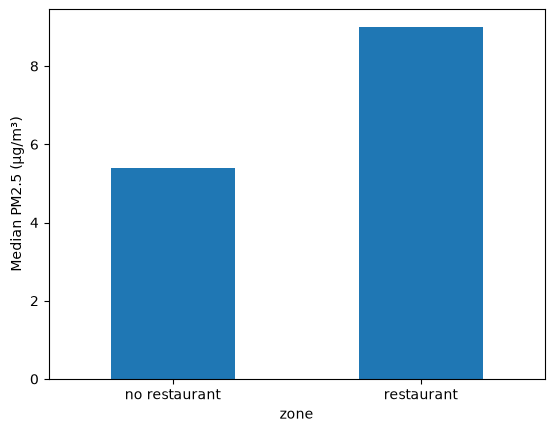

In [48]:
import matplotlib.pyplot as plt

medians_chart = df.groupby(["zone"])["pm2.5_atm"].median()
medians_chart.plot(kind="bar", ylabel="Median PM2.5 (µg/m³)", rot=0)

In [ ]:
## now if I wanna have a chart without my three outliers sensors ##
bad = [285560, 319136, 150174]
clean_df = df.query("sensor_index not in @bad")
clean_df.groupby(["zone","sensor_index"])["pm2.5_atm"].agg(["mean", "median", "std", "count"])

mean  median        std  count
zone          sensor_index                                     
no restaurant 90247          8.022632     6.0   9.261325   2903
              184329         5.391905     3.7   7.640139   2903
              306402         4.627674     2.5   8.693469   2898
restaurant    29183         11.428134     8.4  13.651766   2904
              172823        12.158629     8.5  15.361478   2903
              189249        10.309606     7.2  14.226254   2894
              295845        14.913926    11.6  15.991812   2901

<Axes: xlabel='sensor_index', ylabel='Median PM2.5 (µg/m³)'>

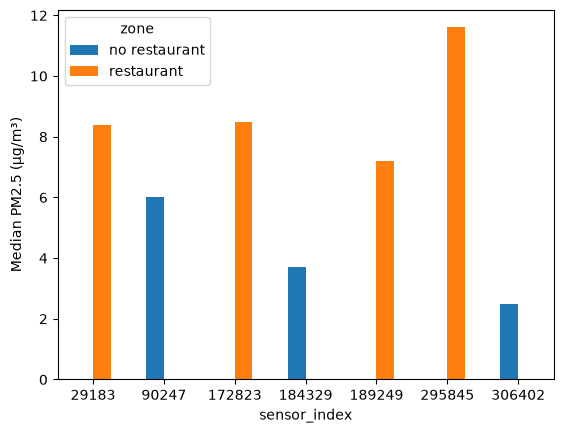

In [55]:
clean_medians_chart = clean_df.groupby(["sensor_index", "zone"])["pm2.5_atm"].median().unstack()
clean_medians_chart.plot(kind="bar", ylabel="Median PM2.5 (µg/m³)", rot=0)